In [1]:
# ==========================================
# STEP 1 : Import Libraries
# ==========================================

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

# Plot Style
plt.style.use("ggplot")

print("Libraries Imported Successfully!")

Libraries Imported Successfully!


In [2]:
# ==========================================
# STEP 2 : Load Dataset
# ==========================================

df = pd.read_csv("winequality-red.csv")

print("Dataset Loaded Successfully!")

Dataset Loaded Successfully!


In [3]:
# First 5 rows
df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [4]:
# Last 5 rows
df.tail()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
1594,6.2,0.600,0.08,2.0,0.090,32.0,44.0,0.99490,3.45,0.58,10.5,5
1595,5.9,0.550,0.10,2.2,0.062,39.0,51.0,0.99512,3.52,0.76,11.2,6
1596,6.3,0.510,0.13,2.3,0.076,29.0,40.0,0.99574,3.42,0.75,11.0,6
1597,5.9,0.645,0.12,2.0,0.075,32.0,44.0,0.99547,3.57,0.71,10.2,5
1598,6.0,0.310,0.47,3.6,0.067,18.0,42.0,0.99549,3.39,0.66,11.0,6


In [5]:
print("Rows :", df.shape[0])
print("Columns :", df.shape[1])

Rows : 1599
Columns : 12


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


In [7]:
df.dtypes

fixed acidity           float64
volatile acidity        float64
citric acid             float64
residual sugar          float64
chlorides               float64
free sulfur dioxide     float64
total sulfur dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
quality                   int64
dtype: object

In [8]:
df.isnull().sum()

fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

In [9]:
print("Duplicate Rows :", df.duplicated().sum())

Duplicate Rows : 240


In [10]:
df = df.drop_duplicates()

print("New Shape :", df.shape)

New Shape : (1359, 12)


In [11]:
df.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1359.000000,1359.000000,1359.000000,1359.000000,1359.000000,1359.000000,1359.000000,1359.000000,1359.000000,1359.000000,1359.000000,1359.000000
mean,8.310596,0.529478,0.272333,2.523400,0.088124,15.893304,46.825975,0.996709,3.309787,0.658705,10.432315,5.623252
std,1.736990,0.183031,0.195537,1.352314,0.049377,10.447270,33.408946,0.001869,0.155036,0.170667,1.082065,0.823578
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000
25%,7.100000,0.390000,0.090000,1.900000,0.070000,7.000000,22.000000,0.995600,3.210000,0.550000,9.500000,5.000000
50%,7.900000,0.520000,0.260000,2.200000,0.079000,14.000000,38.000000,0.996700,3.310000,0.620000,10.200000,6.000000
75%,9.200000,0.640000,0.430000,2.600000,0.091000,21.000000,63.000000,0.997820,3.400000,0.730000,11.100000,6.000000
max,15.900000,1.580000,1.000000,15.500000,0.611000,72.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000


In [12]:
# ==========================================
# Convert Quality into Binary Class
# ==========================================

df["quality_label"] = df["quality"].apply(
    lambda x: 1 if x >= 7 else 0
)

df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,quality_label
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,0
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,0
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,0
5,7.4,0.66,0.00,1.8,0.075,13.0,40.0,0.9978,3.51,0.56,9.4,5,0


In [13]:
df["quality_label"].value_counts()

quality_label
0    1175
1     184
Name: count, dtype: int64

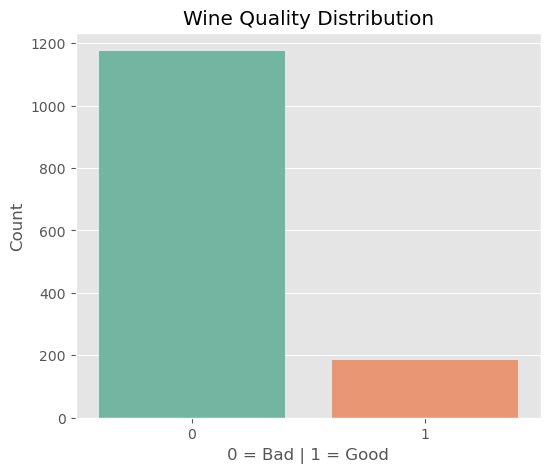

In [14]:
plt.figure(figsize=(6,5))

sns.countplot(
    x="quality_label",
    data=df,
    palette="Set2"
)

plt.title("Wine Quality Distribution")
plt.xlabel("0 = Bad | 1 = Good")
plt.ylabel("Count")

plt.show()

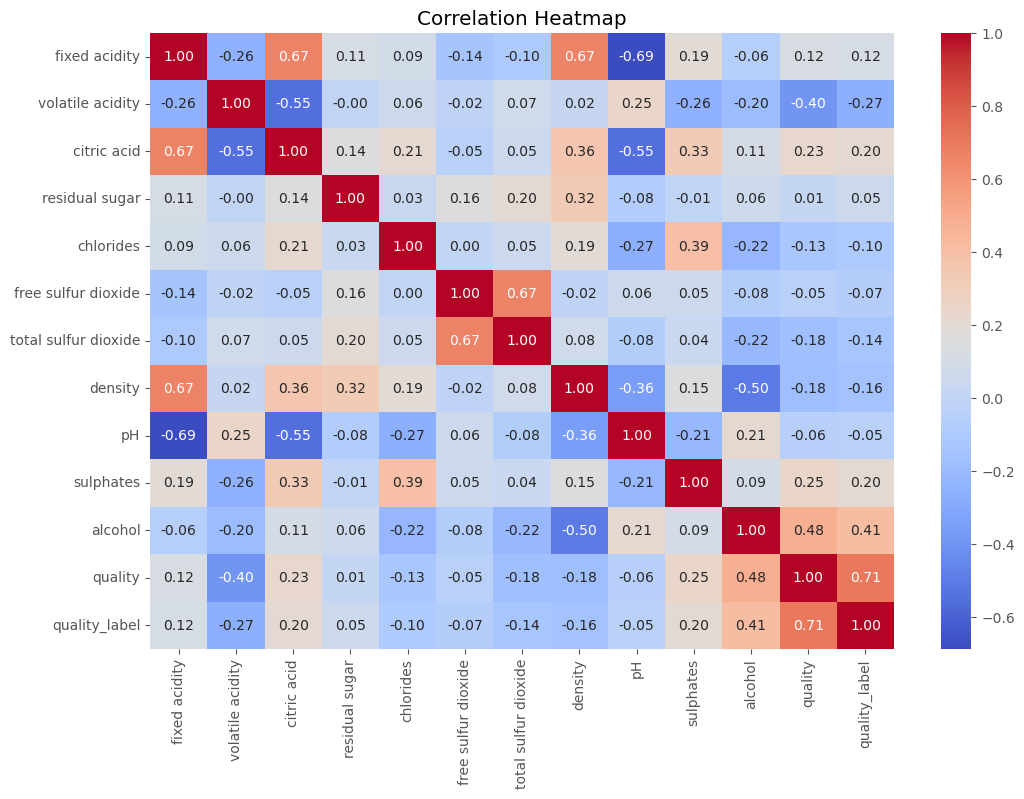

In [15]:
plt.figure(figsize=(12,8))

sns.heatmap(
    df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.show()

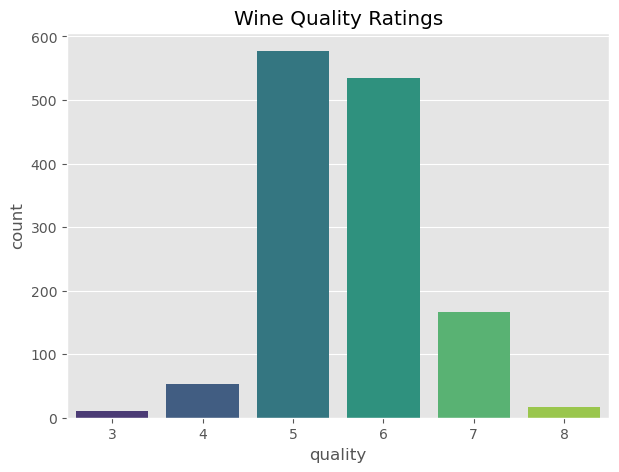

In [16]:
plt.figure(figsize=(7,5))

sns.countplot(
    x="quality",
    data=df,
    palette="viridis"
)

plt.title("Wine Quality Ratings")

plt.show()

In [17]:
# Features
X = df.drop(["quality", "quality_label"], axis=1)

# Target
y = df["quality_label"]

print("Feature Shape :", X.shape)
print("Target Shape :", y.shape)

Feature Shape : (1359, 11)
Target Shape : (1359,)


In [18]:
print(X.columns)

Index(['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
       'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density',
       'pH', 'sulphates', 'alcohol'],
      dtype='object')


In [19]:
print("Features")

display(X.head())

print("\nTarget")

display(y.head())

Features


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8
5,7.4,0.66,0.00,1.8,0.075,13.0,40.0,0.9978,3.51,0.56,9.4



Target


0    0
1    0
2    0
3    0
5    0
Name: quality_label, dtype: int64

In [20]:
# ==========================================
# STEP 23 : Import ML Libraries
# ==========================================

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    roc_auc_score
)

from sklearn.model_selection import GridSearchCV

import joblib

print("ML Libraries Imported Successfully!")

ML Libraries Imported Successfully!


In [21]:
# ==========================================
# STEP 24 : Train Test Split
# ==========================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Shape :", X_train.shape)
print("Testing Shape :", X_test.shape)

Training Shape : (1087, 11)
Testing Shape : (272, 11)


In [22]:
# ==========================================
# STEP 25 : Standard Scaling
# ==========================================

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

print("Scaling Completed!")

Scaling Completed!


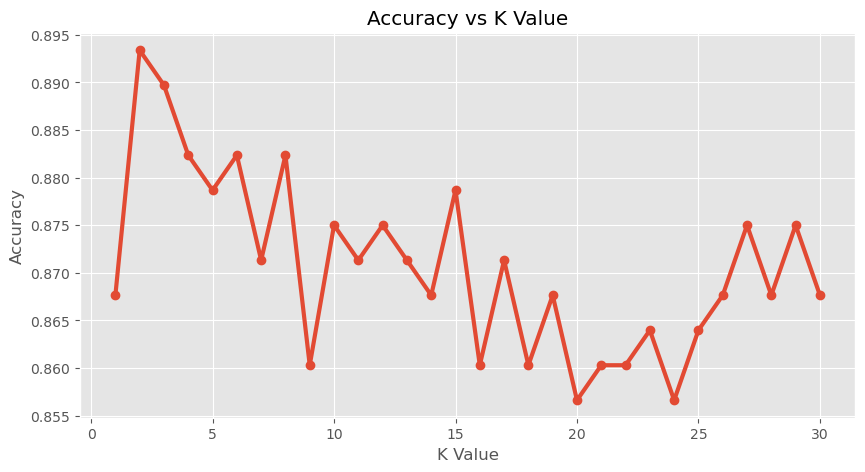

In [23]:
# ==========================================
# STEP 26 : Find Best K
# ==========================================

accuracy = []

for k in range(1,31):

    model = KNeighborsClassifier(n_neighbors=k)

    model.fit(X_train_scaled, y_train)

    pred = model.predict(X_test_scaled)

    accuracy.append(accuracy_score(y_test, pred))

plt.figure(figsize=(10,5))

plt.plot(range(1,31), accuracy,
         marker='o',
         linewidth=3)

plt.title("Accuracy vs K Value")

plt.xlabel("K Value")

plt.ylabel("Accuracy")

plt.grid(True)

plt.show()

In [24]:
# ==========================================
# STEP 27 : GridSearchCV
# ==========================================

param_grid = {
    'n_neighbors':[3,5,7,9,11,13,15],
    'weights':['uniform','distance'],
    'metric':['euclidean','manhattan','minkowski']
}

grid = GridSearchCV(
    estimator=KNeighborsClassifier(),
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

grid.fit(X_train_scaled, y_train)

print("Best Parameters")

print(grid.best_params_)

print()

print("Best Accuracy")

print(grid.best_score_)

Best Parameters
{'metric': 'manhattan', 'n_neighbors': 15, 'weights': 'distance'}

Best Accuracy
0.8776434278949816


In [25]:
# ==========================================
# STEP 28 : Final KNN Model
# ==========================================

knn = grid.best_estimator_

knn.fit(X_train_scaled, y_train)

print("Model Trained Successfully!")

Model Trained Successfully!


In [26]:
# ==========================================
# STEP 29 : Prediction
# ==========================================

y_pred = knn.predict(X_test_scaled)

y_prob = knn.predict_proba(X_test_scaled)[:,1]

In [27]:
accuracy = accuracy_score(y_test,y_pred)

print("Accuracy :",round(accuracy*100,2),"%")

Accuracy : 86.76 %


In [28]:
precision = precision_score(y_test,y_pred)

print("Precision :",round(precision,3))

Precision : 0.52


In [29]:
recall = recall_score(y_test,y_pred)

print("Recall :",round(recall,3))

Recall : 0.351


In [30]:
f1 = f1_score(y_test,y_pred)

print("F1 Score :",round(f1,3))

F1 Score : 0.419


In [31]:
auc = roc_auc_score(y_test,y_prob)

print("ROC AUC :",round(auc,3))

ROC AUC : 0.81


In [32]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.90      0.95      0.93       235
           1       0.52      0.35      0.42        37

    accuracy                           0.87       272
   macro avg       0.71      0.65      0.67       272
weighted avg       0.85      0.87      0.86       272



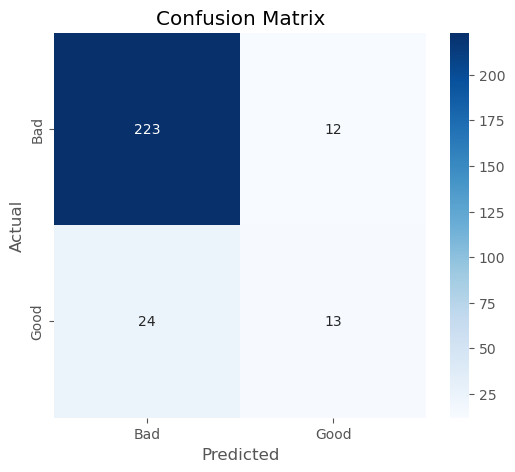

In [33]:
cm = confusion_matrix(y_test,y_pred)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=["Bad","Good"],
    yticklabels=["Bad","Good"]
)

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.title("Confusion Matrix")

plt.show()

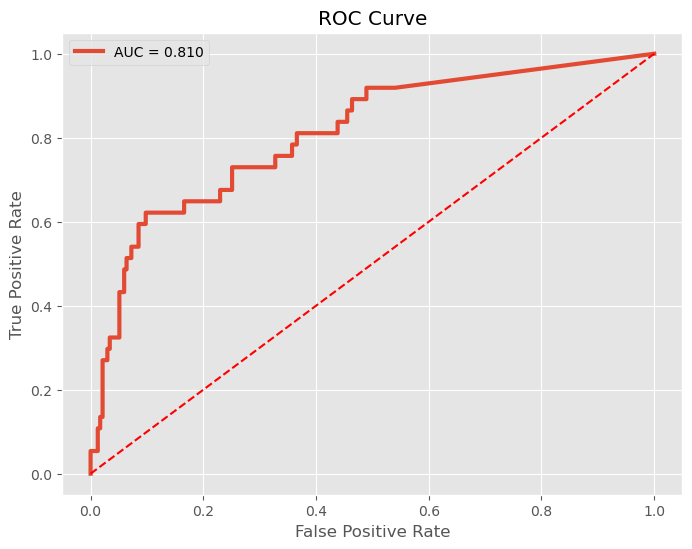

In [34]:
fpr,tpr,threshold = roc_curve(y_test,y_prob)

plt.figure(figsize=(8,6))

plt.plot(
    fpr,
    tpr,
    linewidth=3,
    label="AUC = {:.3f}".format(auc)
)

plt.plot([0,1],[0,1],'r--')

plt.xlabel("False Positive Rate")

plt.ylabel("True Positive Rate")

plt.title("ROC Curve")

plt.legend()

plt.grid(True)

plt.show()

In [35]:
from sklearn.inspection import permutation_importance

result = permutation_importance(
    knn,
    X_test_scaled,
    y_test,
    n_repeats=10,
    random_state=42
)

importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": result.importances_mean
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

importance

,Feature,Importance
10,alcohol,0.009559
3,residual sugar,0.002941
6,total sulfur dioxide,0.001838
9,sulphates,-0.001838
2,citric acid,-0.002206
1,volatile acidity,-0.002941
5,free sulfur dioxide,-0.002941
4,chlorides,-0.004779
7,density,-0.004779
0,fixed acidity,-0.008088


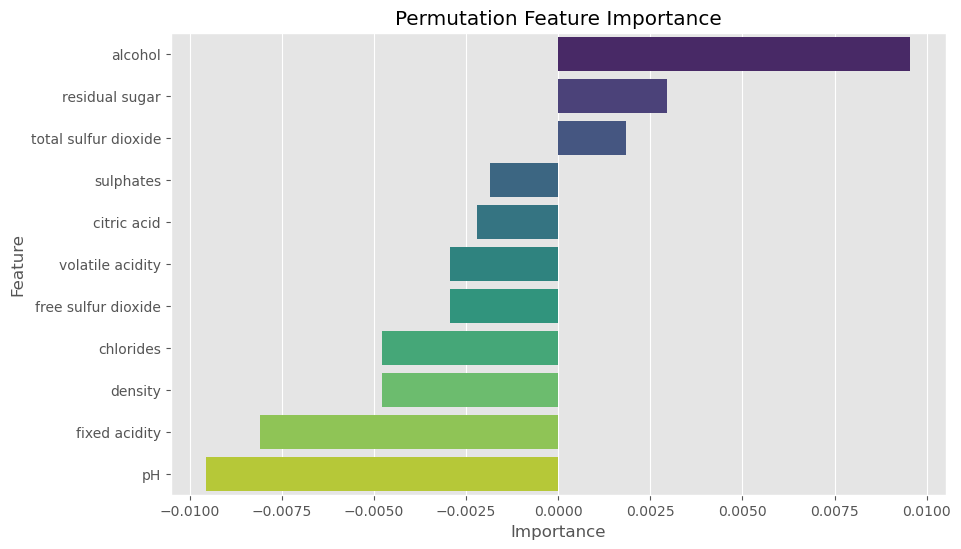

In [36]:
plt.figure(figsize=(10,6))

sns.barplot(
    x="Importance",
    y="Feature",
    data=importance,
    palette="viridis"
)

plt.title("Permutation Feature Importance")

plt.show()

In [37]:
# ==========================================
# STEP 40 : Save Files
# ==========================================

joblib.dump(knn,"knn_model.pkl")

joblib.dump(scaler,"scaler.pkl")

joblib.dump(list(X.columns),"feature_names.pkl")

print("Model Saved Successfully!")

Model Saved Successfully!


In [38]:
loaded_model = joblib.load("knn_model.pkl")

loaded_scaler = joblib.load("scaler.pkl")

loaded_features = joblib.load("feature_names.pkl")

sample = X.iloc[[0]]

sample_scaled = loaded_scaler.transform(sample)

prediction = loaded_model.predict(sample_scaled)

print("Prediction :", prediction)

print("Feature Names :")

print(loaded_features)

Prediction : [0]
Feature Names :
['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol']
